### Carregando bibliotecas e dados

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import json


In [6]:
#pd.set_option('display.max_rows', None)
#pd.set_option('display.max_columns', None)

pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')

In [7]:
df = pd.read_csv("data.csv")

/tmp/ipykernel_523/3477112522.py:1: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data.csv")


In [8]:
df_soc = pd.read_csv("societies.csv")[["ID", "Name"]].iloc[:339].copy()
df_soc

,ID,Name
0,B72,!Kung
1,B296,Kuskowagmut
2,B322,Syilx
3,B335,Round Lake Ojibwa
4,B339,North Albany Ojibwa
...,...,...
334,B215,Spring Valley Shoshoni
335,B224,Antelope Valley Shoshoni
336,B272,Chehalis
337,B293,Gitxsan


In [9]:
df_B009 = df[df["Var_ID"] == "B009"].copy().reset_index(drop=True)
df_B009.drop(columns=["ID", "Code_ID", "Source", "source_coded_data", "admin_comment"], inplace=True)

df_B021 = df[(df["Var_ID"] == "B021") & (df["Value"].notna())].copy().reset_index(drop=True)
df_B021.drop(columns=["ID", "Code_ID", "Source", "source_coded_data", "admin_comment"], inplace=True)

**Obs:** \
B009 se refere ao *nomadismo* ou *sedentarismo* da sociedade \
B021 se refere à *idade média* ao casar das mulheres

In [10]:
df_B009

,Soc_ID,Var_ID,Value,Comment,sub_case,year
0,B1,B009,Mobile,NaN,NaN,1970
1,B10,B009,Mobile,NaN,NaN,1900
2,B100,B009,Mobile,NaN,NaN,NaN
3,B101,B009,Mobile,NaN,NaN,1934
4,B102,B009,Mobile,NaN,NaN,1909
...,...,...,...,...,...,...
334,B95,B009,Mobile,NaN,NaN,1920
335,B96,B009,Mobile,NaN,NaN,1880
336,B97,B009,Mobile,NaN,NaN,1930
337,B98,B009,Mobile,"Changed to ""1"" based on Binford (2001:279): ""T...",NaN,1926


In [11]:
df_B021

,Soc_ID,Var_ID,Value,Comment,sub_case,year
0,B10,B021,14,NaN,NaN,1900
1,B100,B021,11,NaN,NaN,NaN
2,B101,B021,13,NaN,NaN,1934
3,B103,B021,14,NaN,NaN,1928
4,B105,B021,10,NaN,NaN,1900
...,...,...,...,...,...,...
200,B95,B021,9,NaN,NaN,1920
201,B96,B021,13,NaN,refers specifically to Yalandji,1880
202,B97,B021,9,NaN,NaN,1930
203,B98,B021,13,NaN,NaN,1926


In [12]:
print(f"Valores duplicados B009: {df_B009["Soc_ID"].duplicated().sum()}")
print(f"Valores duplicados B021: {df_B021["Soc_ID"].duplicated().sum()}")

Valores duplicados B009: 0
Valores duplicados B021: 8


In [13]:
for _, row in df_B021.dropna(subset=["Comment"]).iterrows():
    print(f"Society {row['Soc_ID']}")
    print(f"Comment: {row['Comment']}\n")

Society B14
Comment: Note, for this society, Binford provided two estimates (13, 17); this entry is one of those estimates

Society B14
Comment: Note, for this society, Binford provided two estimates (13, 17); this entry is one of those estimates

Society B202
Comment: Note, for this society, Binford provided two estimates (12, 13); this entry is one of those estimates

Society B202
Comment: Note, for this society, Binford provided two estimates (12, 13); this entry is one of those estimates

Society B22
Comment: Note, first of two estimates provided by Binford for this society (16, 16)

Society B22
Comment: Note, second of two estimates provided by Binford for this society (16, 16)

Society B226
Comment: Note, for this society, Binford provided two estimates (13.5, 15); this entry is one of those estimates

Society B226
Comment: Note, for this society, Binford provided two estimates (13.5, 15); this entry is one of those estimates

Society B243
Comment: Note: estimate is said to be fo

#### Lidando com sociedades com valores duplicados

In [14]:
df_B021["Value"] = pd.to_numeric(df_B021["Value"])
df_B021_corrigido = df_B021.groupby(["Soc_ID", "sub_case"], dropna=False, as_index=False)["Value"].mean()
df_B021_corrigido

,Soc_ID,sub_case,Value
0,B10,NaN,14.0
1,B100,NaN,11.0
2,B101,NaN,13.0
3,B103,NaN,14.0
4,B105,NaN,10.0
...,...,...,...
194,B95,NaN,9.0
195,B96,refers specifically to Yalandji,13.0
196,B97,NaN,9.0
197,B98,NaN,13.0


In [15]:
print(f"Valores duplicados B021: {df_B021_corrigido["Soc_ID"].duplicated().sum()}")

Valores duplicados B021: 2


### Criando conjunto de dados para teste

In [16]:
### Juntando as variáveis
df_teste = pd.merge(
    df_B009[["Soc_ID", "Value"]],
    df_B021_corrigido[["Soc_ID", "sub_case", "Value"]],
    on="Soc_ID",
    how="inner",
    suffixes=("_B009", "_B021"),
    validate="one_to_many"
)

In [17]:
### Nomeando as sociedades e as variáveis
df_teste = df_teste.merge(
    df_soc,
    left_on="Soc_ID",
    right_on="ID",
    how="left",
)
df_teste = df_teste[["Name", "sub_case", "Value_B009", "Value_B021"]]
df_teste.columns = ["Society", "sub_case", "Mobility", "Avg age of marriage of women"]
df_teste

,Society,sub_case,Mobility,Avg age of marriage of women
0,Vedda,NaN,Mobile,14.0
1,Worrorra,NaN,Mobile,11.0
2,Kija,NaN,Mobile,13.0
3,Kaiadilt,NaN,Mobile,14.0
4,Mamu,NaN,Mobile,10.0
...,...,...,...,...
194,Tiwi,NaN,Mobile,9.0
195,Kuku (Yalanji),refers specifically to Yalandji,Mobile,13.0
196,Anindilyagwa,NaN,Mobile,9.0
197,Walmbaria,NaN,Mobile,13.0


### Análise descritiva

#### Estatísticas descritivas das variáveis

In [18]:
df_teste.head()

,Society,sub_case,Mobility,Avg age of marriage of women
0,Vedda,NaN,Mobile,14.0
1,Worrorra,NaN,Mobile,11.0
2,Kija,NaN,Mobile,13.0
3,Kaiadilt,NaN,Mobile,14.0
4,Mamu,NaN,Mobile,10.0


In [19]:
# Missing values
print(df_teste.isnull().sum())

Society                           0
sub_case                        194
Mobility                          0
Avg age of marriage of women      0
dtype: int64


In [20]:
print(df_teste["Avg age of marriage of women"].describe())

count    199.000000
mean      14.132915
std        2.486739
min        5.000000
25%       13.000000
50%       14.000000
75%       15.500000
max       22.000000
Name: Avg age of marriage of women, dtype: float64


In [21]:
print(df_teste["Mobility"].describe())

count        199
unique         2
top       Mobile
freq         141
Name: Mobility, dtype: object


In [22]:
print(df_teste.loc[df_teste["Mobility"] == "Sedentary", "Avg age of marriage of women"].describe())

count    58.000000
mean     14.665517
std       2.379632
min       5.000000
25%      13.625000
50%      14.500000
75%      15.875000
max      20.000000
Name: Avg age of marriage of women, dtype: float64


In [23]:
print(df_teste.loc[df_teste["Mobility"] == "Mobile", "Avg age of marriage of women"].describe())

count    141.000000
mean      13.913830
std        2.504875
min        6.500000
25%       13.000000
50%       14.000000
75%       15.500000
max       22.000000
Name: Avg age of marriage of women, dtype: float64


#### Gráficos das variáveis

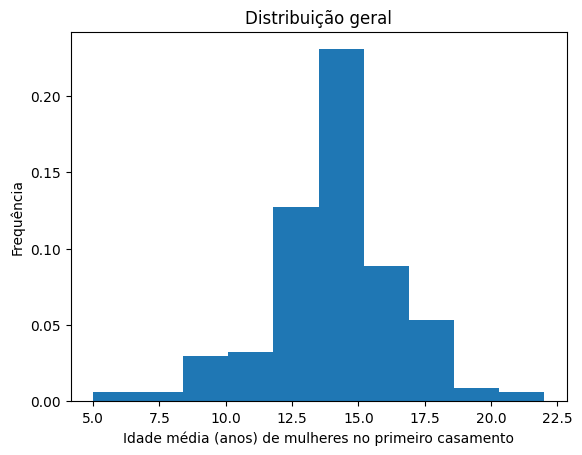

In [24]:
### Histograma geral

plt.figure()
plt.hist(df_teste["Avg age of marriage of women"], density=True)
plt.xlabel("Idade média (anos) de mulheres no primeiro casamento")
plt.ylabel("Frequência")
plt.title("Distribuição geral")
plt.show()

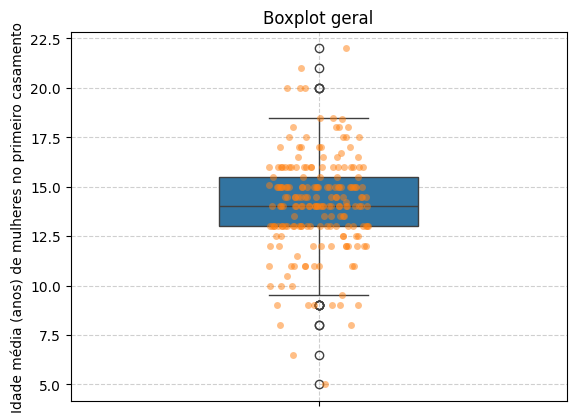

In [25]:
### Boxplot geral

plt.figure()
sns.boxplot(df_teste["Avg age of marriage of women"], width=0.4)
sns.stripplot(df_teste["Avg age of marriage of women"], alpha=0.5)
plt.title("Boxplot geral")
plt.ylabel('Idade média (anos) de mulheres no primeiro casamento')
plt.grid(linestyle='--', alpha=0.6)
plt.show()

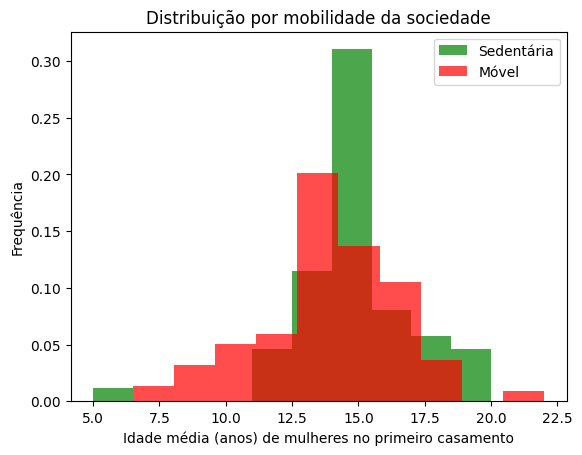

In [26]:
### histogramas por mobilidade da sociedade

plt.figure()

plt.hist(df_teste.loc[df_teste["Mobility"] == "Sedentary", "Avg age of marriage of women"],
         density=True,
         color="green",
         alpha=0.7,
         label="Sedentária"
         )
plt.hist(df_teste.loc[df_teste["Mobility"] == "Mobile", "Avg age of marriage of women"],
         density=True,
         color="red",
         alpha=0.7,
         label="Móvel"
         )

plt.xlabel("Idade média (anos) de mulheres no primeiro casamento")
plt.ylabel("Frequência")
plt.title("Distribuição por mobilidade da sociedade")
plt.legend()
plt.show()

/tmp/ipykernel_523/3958396187.py:16: UserWarning: 
The palette list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  sns.stripplot(


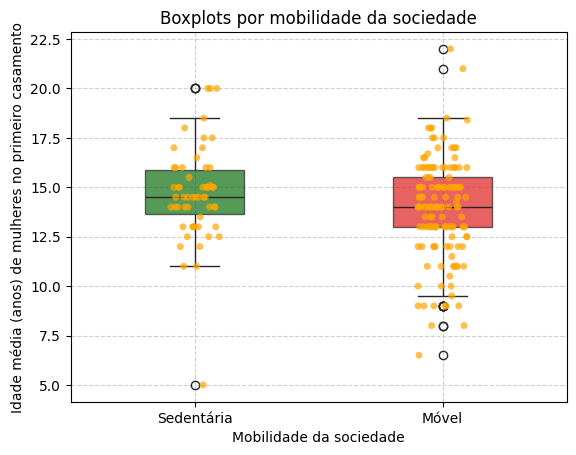

In [27]:
### Boxplot por mobilidade da sociedade

plt.figure()

sns.boxplot(
            data=df_teste,
            x="Mobility",
            y="Avg age of marriage of women",
            order=["Sedentary", "Mobile"],
            hue="Mobility",
            palette=["red", "green"],
            width=0.4,
            boxprops={"alpha": 0.7}
)

sns.stripplot(
            data=df_teste,
            x="Mobility",
            y="Avg age of marriage of women",
            order=["Sedentary", "Mobile"],
            hue="Mobility",
            palette=["orange"],
            alpha=0.7
)

plt.title("Boxplots por mobilidade da sociedade")
plt.xticks(
    ticks=[0, 1],
    labels=["Sedentária", "Móvel"]
)
plt.xlabel("Mobilidade da sociedade")
plt.ylabel("Idade média (anos) de mulheres no primeiro casamento")
plt.grid(linestyle='--', alpha=0.6)
plt.show()

# Testes de Hipótese e Intervalos de Confiança


#### Teste Bootstrap de Igualdade entre variâncias

In [28]:
idades_nomades = df_teste.loc[
    df_teste["Mobility"] == "Mobile",
    "Avg age of marriage of women"
].dropna().to_numpy()

idades_sedentarias = df_teste.loc[
    df_teste["Mobility"] == "Sedentary",
    "Avg age of marriage of women"
].dropna().to_numpy()

import numpy as np

# Vetores com as idades ao casar de cada grupo
nomades = np.asarray(idades_nomades, dtype=float)
sedentarias = np.asarray(idades_sedentarias, dtype=float)

# Estatística observada: diferença entre as variâncias
T_obs = np.var(nomades, ddof=1) - np.var(sedentarias, ddof=1)

# Variância comum estimada sob H0
n1, n2 = len(nomades), len(sedentarias)

media1, media2 = nomades.mean(), sedentarias.mean()

res1 = nomades - media1
res2 = sedentarias - media2

variancia_comum = (np.sum(res1**2) + np.sum(res2**2)) / (n1 + n2 - 2)

# Ajusta os resíduos para impor a mesma variância populacional
res1 = res1 * np.sqrt(variancia_comum / np.var(res1, ddof=0))
res2 = res2 * np.sqrt(variancia_comum / np.var(res2, ddof=0))

# Bootstrap sob H0
B = 9999
rng = np.random.default_rng(42)

T_boot_var = np.empty(B)

for b in range(B):
    amostra1 = rng.choice(res1, size=n1, replace=True)
    amostra2 = rng.choice(res2, size=n2, replace=True)

    T_boot_var[b] = np.var(amostra1, ddof=1)- np.var(amostra2, ddof=1)

# Valor-p bilateral
p_valor = (
    1 + np.sum(np.abs(T_boot_var) >= abs(T_obs))
) / (B + 1)

print("Variância dos nômades:", np.var(nomades, ddof=1))
print("Variância dos sedentários:", np.var(sedentarias, ddof=1))
print("Diferença observada:", T_obs)
print("Valor-p bootstrap:", p_valor)

Variância dos nômades: 6.274396656534955
Variância dos sedentários: 5.662649727767695
Diferença observada: 0.6117469287672597
Valor-p bootstrap: 0.7706


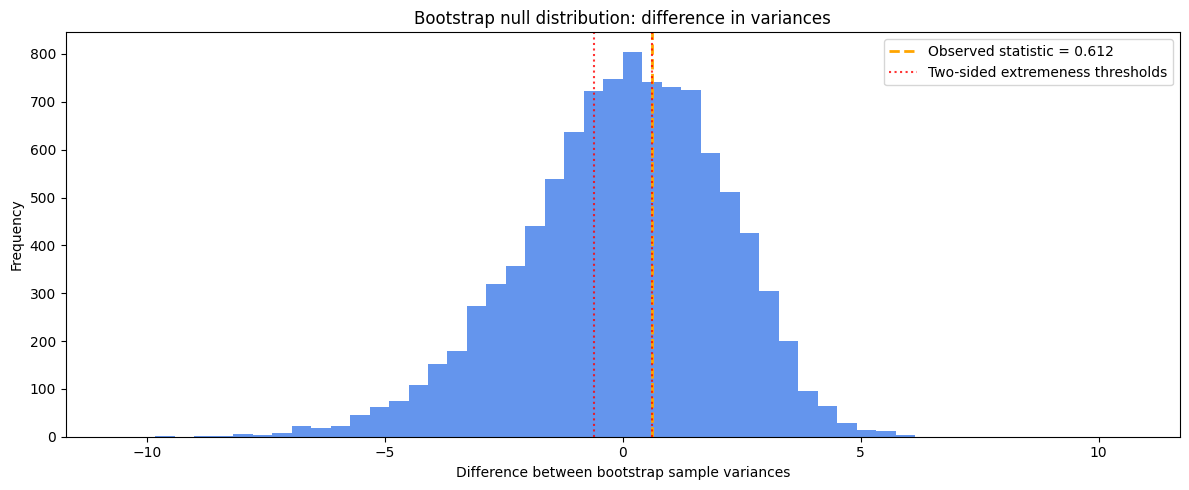

In [34]:
plt.figure(figsize=(12, 5))

plt.hist(
    T_boot_var,
    bins=52,
    range=(-max(1, np.max(np.abs(T_boot_var)), abs(T_obs)) * 1.12,
           max(1, np.max(np.abs(T_boot_var)), abs(T_obs)) * 1.12),
    color="cornflowerblue",
    edgecolor="none"
)

plt.axvline(
    T_obs,
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"Observed statistic = {T_obs:.3f}"
)

plt.axvline(
    -abs(T_obs),
    color="red",
    linestyle=":",
    alpha=0.8
)

plt.axvline(
    abs(T_obs),
    color="red",
    linestyle=":",
    alpha=0.8,
    label="Two-sided extremeness thresholds"
)

plt.title("Bootstrap null distribution: difference in variances")
plt.xlabel("Difference between bootstrap sample variances")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

#### Testes de Permutação para Estatísticas Variadas

In [30]:
# Estatísticas observadas originalmente
T_media = nomades.mean() - sedentarias.mean()

T_mediana = np.median(nomades) - np.median(sedentarias)

T_HL = np.median(nomades[:, None] - sedentarias[None, :])

# Teste de permutação
B = 9999
rng = np.random.default_rng(67)

dados = np.concatenate([nomades, sedentarias])
n_nomades = len(nomades)

T_perm_media = np.empty(B)
T_perm_mediana = np.empty(B)
T_perm_HL = np.empty(B)

for b in range(B):
    permutados = rng.permutation(dados)

    grupo_n = permutados[:n_nomades]
    grupo_s = permutados[n_nomades:]

    T_perm_media[b] = grupo_n.mean() - grupo_s.mean()
    T_perm_mediana[b] = (np.median(grupo_n) - np.median(grupo_s))
    T_perm_HL[b] = np.median(grupo_n[:, None] - grupo_s[None, :])

# Valores-p bilaterais
def valor_p_permutacao(T_obs, T_perm):
    return (
        1 + np.sum(np.abs(T_perm) >= abs(T_obs))
    ) / (len(T_perm) + 1)

p_media = valor_p_permutacao(T_media, T_perm_media)
p_mediana = valor_p_permutacao(T_mediana, T_perm_mediana)
p_HL = valor_p_permutacao(T_HL, T_perm_HL)

# Resultados
print("Diferença de médias:", T_media)
print("Valor-p (médias):", p_media)

print("\nDiferença de medianas:", T_mediana)
print("Valor-p (medianas):", p_mediana)

print("\nEstimador de Hodges-Lehmann:", T_HL)
print("Valor-p (Hodges-Lehmann):", p_HL)

print("\n \nMédia dos nômades:", nomades.mean())
print("Média das sedentárias:", sedentarias.mean())
print("Diferença observada:", T_obs)
print("Valor-p do teste de permutação:", p_valor)

Diferença de médias: -0.7516874541452694
Valor-p (médias): 0.0523

Diferença de medianas: -0.5
Valor-p (medianas): 0.6402

Estimador de Hodges-Lehmann: -0.5
Valor-p (Hodges-Lehmann): 0.3528

 
Média dos nômades: 13.913829787234041
Média das sedentárias: 14.66551724137931
Diferença observada: 0.6117469287672597
Valor-p do teste de permutação: 0.7706


Tamanhos dos grupos: 141 58
Número de permutações: 9999 9999

--- Diferença de medianas ---
Observado: -0.500000
Média das permutações: -0.058756
Desvio-padrão: 0.463971
Mínimo: -1.000000
Máximo: 2.000000
Valores distintos: 15
Proporção exatamente zero: 11.8712%
Proporção tão ou mais extrema que a observada: 64.0164%

--- Estimador de Hodges-Lehmann ---
Observado: -0.500000
Média das permutações: 0.010156
Desvio-padrão: 0.350192
Mínimo: -1.000000
Máximo: 1.500000
Valores distintos: 66
Proporção exatamente zero: 61.9862%
Proporção tão ou mais extrema que a observada: 35.2735%



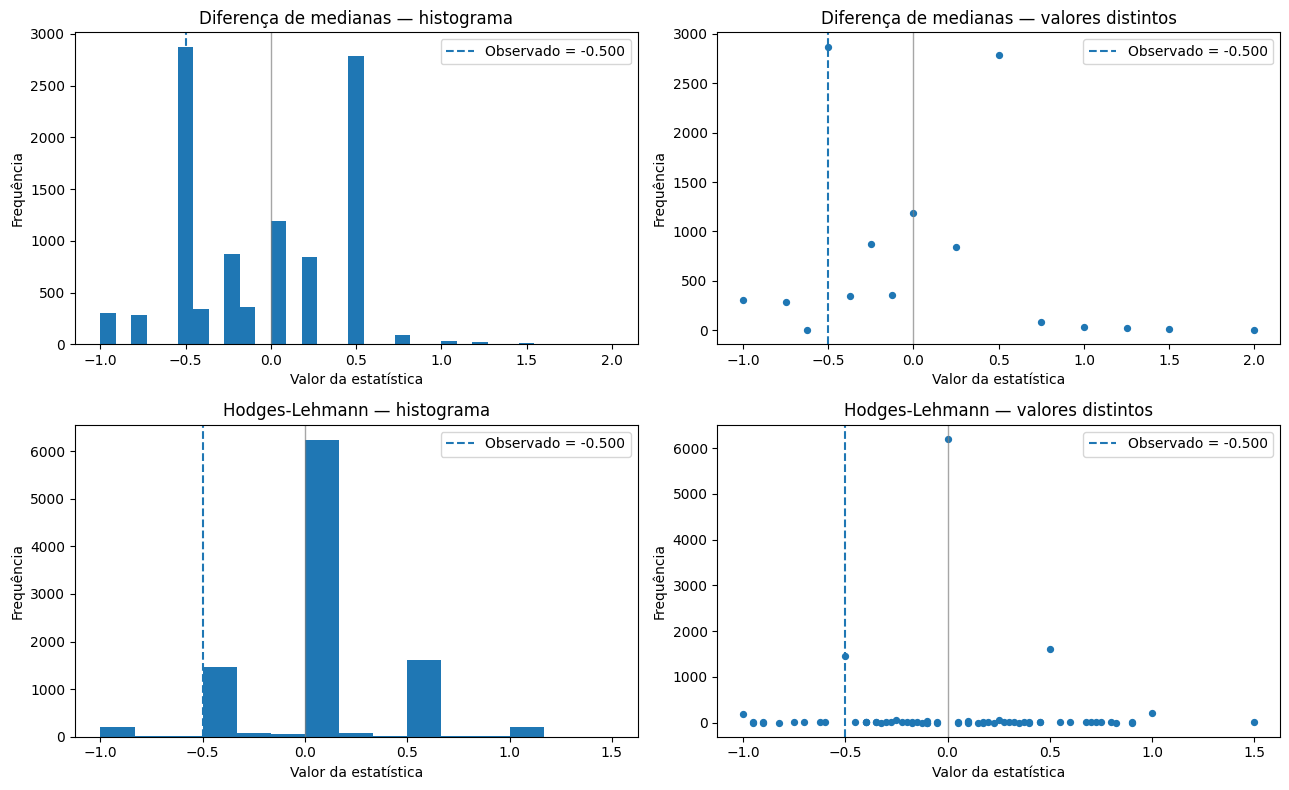

In [42]:

import numpy as np
import matplotlib.pyplot as plt

# Converter para arrays e remover valores ausentes
nomades = np.asarray(nomades, dtype=float)
sedentarias = np.asarray(sedentarias, dtype=float)

nomades = nomades[np.isfinite(nomades)]
sedentarias = sedentarias[np.isfinite(sedentarias)]

T_perm_mediana = np.asarray(T_perm_mediana, dtype=float)
T_perm_HL = np.asarray(T_perm_HL, dtype=float)

# Estatísticas observadas
T_mediana_obs = np.median(nomades) - np.median(sedentarias)

# Hodges-Lehmann: mediana de todas as diferenças entre pares
diferencas_obs = (
    nomades[:, None] - sedentarias[None, :]
)
T_HL_obs = np.median(diferencas_obs)

# Verificações básicas
print("Tamanhos dos grupos:", len(nomades), len(sedentarias))
print("Número de permutações:", len(T_perm_mediana), len(T_perm_HL))
print()

def diagnostico(nome, valores, observado):
    valores = np.asarray(valores, dtype=float)
    valores = valores[np.isfinite(valores)]

    print(f"--- {nome} ---")
    print(f"Observado: {observado:.6f}")
    print(f"Média das permutações: {np.mean(valores):.6f}")
    print(f"Desvio-padrão: {np.std(valores, ddof=1):.6f}")
    print(f"Mínimo: {np.min(valores):.6f}")
    print(f"Máximo: {np.max(valores):.6f}")
    print(f"Valores distintos: {len(np.unique(valores))}")
    print(f"Proporção exatamente zero: {np.mean(valores == 0):.4%}")
    print(
        "Proporção tão ou mais extrema que a observada:",
        f"{np.mean(np.abs(valores) >= abs(observado)):.4%}"
    )
    print()

    return valores

T_perm_mediana = diagnostico(
    "Diferença de medianas",
    T_perm_mediana,
    T_mediana_obs
)

T_perm_HL = diagnostico(
    "Estimador de Hodges-Lehmann",
    T_perm_HL,
    T_HL_obs
)

# Gráficos: histograma e distribuição dos valores distintos
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

graficos = [
    (axes[0, 0], T_perm_mediana, T_mediana_obs,
     "Diferença de medianas — histograma"),
    (axes[0, 1], T_perm_mediana, T_mediana_obs,
     "Diferença de medianas — valores distintos"),
    (axes[1, 0], T_perm_HL, T_HL_obs,
     "Hodges-Lehmann — histograma"),
    (axes[1, 1], T_perm_HL, T_HL_obs,
     "Hodges-Lehmann — valores distintos")
]

for ax, valores, observado, titulo in graficos:
    if "valores distintos" in titulo:
        unicos, contagens = np.unique(valores, return_counts=True)
        ax.scatter(unicos, contagens, s=18)
        ax.set_ylabel("Frequência")
    else:
        ax.hist(valores, bins="auto")
        ax.set_ylabel("Frequência")

    ax.axvline(
        observado,
        linestyle="--",
        label=f"Observado = {observado:.3f}"
    )
    ax.axvline(0, color="gray", alpha=0.7, linewidth=1)
    ax.set_title(titulo)
    ax.set_xlabel("Valor da estatística")
    ax.legend()

plt.tight_layout()
plt.show()


In [41]:
dados_animacao = {
    # Teste de variâncias — página existente
    "T_obs": float(T_obs),
    "T_boot_var": T_boot_var.tolist(),

    # Teste de permutação
    "T_media": float(T_media),
    "T_mediana": float(T_mediana),
    "T_HL": float(T_HL),
    "T_perm_media": T_perm_media.tolist(),
    "T_perm_mediana": T_perm_mediana.tolist(),
    "T_perm_HL": T_perm_HL.tolist(),

    "illustrative": False
}

with open("bootstrap_data.js", "w", encoding="utf-8") as f:
    f.write("const DATA = ")
    json.dump(dados_animacao, f)
    f.write(";")

#### IC Bootstrap 95% Para a Diferença Entre Médias

In [31]:
diferencas_boot = np.empty(B)

for b in range(B):
    amostra_n = rng.choice(nomades, size=len(nomades), replace=True)
    amostra_s = rng.choice(sedentarias, size=len(sedentarias), replace=True)

    diferencas_boot[b] = amostra_n.mean() - amostra_s.mean()

IC_95 = np.percentile(diferencas_boot, [2.5, 97.5])

print("Diferença de médias:", nomades.mean() - sedentarias.mean())
print("IC de 95%:", IC_95)

Diferença de médias: -0.7516874541452694
IC de 95%: [-1.4833474  -0.02833333]


## Testes Paramétricos

### Razão de Variâncias

In [32]:
n1, n2 = len(nomades), len(sedentarias)
var1 = np.var(nomades, ddof=1)
var2 = np.var(sedentarias, ddof=1)

F_obs = var1 / var2

# Graus de liberdade
gl1 = n1 - 1
gl2 = n2 - 1


p_valor_F = 2 * min(
    stats.f.cdf(F_obs, gl1, gl2),
    stats.f.sf(F_obs, gl1, gl2)
)

print("Variância dos nômades:", var1)
print("Variância dos sedentários:", var2)
print("Razão de variâncias (F):", F_obs)
print("Graus de liberdade:", (gl1, gl2))
print("\nValor-p bilateral:", min(p_valor_F, 1.0))

Variância dos nômades: 6.274396656534955
Variância dos sedentários: 5.662649727767695
Razão de variâncias (F): 1.1080319211282772
Graus de liberdade: (140, 57)

Valor-p bilateral: 0.6702774345886074


#### Teste t Para 2 Populações Independentes, Mesma Variância e IC 95% Para a Diferença Entre Médias

In [33]:
# Estatísticas amostrais
n1, n2 = len(nomades), len(idades_sedentarias)
media1, media2 = idades_nomades.mean(), idades_sedentarias.mean()
var1 = np.var(idades_nomades, ddof=1)
var2 = np.var(idades_sedentarias, ddof=1)

# Diferença observada entre as médias
diferenca = media1 - media2

# Teste t de Student com variâncias iguais
resultado_t = stats.ttest_ind(
    idades_nomades,
    idades_sedentarias,
    equal_var=True,
    alternative="two-sided"
)

# Variância combinada
sp2 = ((n1 - 1)*var1 + (n2 - 1)*var2) / (n1 + n2 - 2)


erro_padrao = np.sqrt(sp2 * (1/n1 + 1/n2))


gl = n1 + n2 - 2

# Intervalo de confiança de 95%
t_critico = stats.t.ppf(0.975, df=gl)

ic_inferior = diferenca - t_critico * erro_padrao
ic_superior = diferenca + t_critico * erro_padrao

# Resultados
print("Média dos nômades:", media1)
print("Média dos sedentários:", media2)
print("\nDiferença entre médias:", diferenca)
print("\nEstatística t:", resultado_t.statistic)
print("Graus de liberdade:", gl)
print("\nValor-p:", resultado_t.pvalue)
print("IC 95% para a diferença:", (float(ic_inferior), float(ic_superior)))

Média dos nômades: 13.913829787234041
Média dos sedentários: 14.66551724137931

Diferença entre médias: -0.7516874541452694

Estatística t: -1.9514714256359882
Graus de liberdade: 197

Valor-p: 0.05241874680397459
IC 95% para a diferença: (-1.5113127547254446, 0.007937846434905693)
